# 02. Biến Đổi Fourier Thời Gian Ngắn (STFT) & Biểu Đồ Phổ Spectrogram
### Short-Time Fourier Transform: Heisenberg-Gabor Uncertainty & Time-Frequency Resolution
**Tác giả:** Antigravity AI Assistant & Biomedical Signal DSP Specialist  
**Mục tiêu:**
1. Khảo sát biểu diễn Thời gian - Tần số (Time-Frequency Representation) trên tín hiệu y sinh thực tế.
2. Kiểm chứng thực nghiệm sự đánh đổi độ phân giải giữa Thời gian và Tần số ($\Delta t \cdot \Delta f \ge rac{1}{4\pi}$) thông qua việc điều chỉnh độ dài cửa sổ trượt (*window length*).
3. Phân tích sự chuyển dịch tần số của tín hiệu EMG cơ bắp và tín hiệu PPG khi chuyển từ trạng thái nghỉ sang vận động.


In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

plt.style.use('default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'figure.dpi': 130
})

DATA_PATH = r"e:\Study\S1\S1.pkl"
with open(DATA_PATH, "rb") as f:
    s1_data = pickle.load(f, encoding="latin1")

# Trích xuất đoạn tín hiệu EMG và PPG dài 20 giây qua pha chuyển tiếp (Transient / Activity)
emg_raw = s1_data['signal']['chest']['EMG'].flatten()
bvp_raw = s1_data['signal']['wrist']['BVP'].flatten()

fs_emg = 700.0
fs_bvp = 64.0

# Chọn đoạn 20 giây có vận động cơ (giây 400 đến 420)
t_start = 400.0
dur = 20.0

emg_seg = emg_raw[int(t_start*fs_emg):int((t_start+dur)*fs_emg)]
bvp_seg = bvp_raw[int(t_start*fs_bvp):int((t_start+dur)*fs_bvp)]

print(f"Đã trích xuất đoạn 20s: EMG ({len(emg_seg)} mẫu), BVP ({len(bvp_seg)} mẫu)")


Đã trích xuất đoạn 20s: EMG (14000 mẫu), BVP (1280 mẫu)


## 1. Khảo sát Sự Đánh Đổi Độ Phân Giải Heisenberg-Gabor
Nguyên lý bất định:
$$\Delta t \cdot \Delta f \ge rac{1}{4\pi}$$
- **Cửa sổ ngắn (Narrow Window):** $\Delta t$ nhỏ (độ phân giải thời gian cao) $ightarrow$ $\Delta f$ lớn (phổ tần số bị mờ).
- **Cửa sổ dài (Wide Window):** $\Delta f$ nhỏ (độ phân giải tần số cao) $ightarrow$ $\Delta t$ lớn (mờ biến cố thời gian).


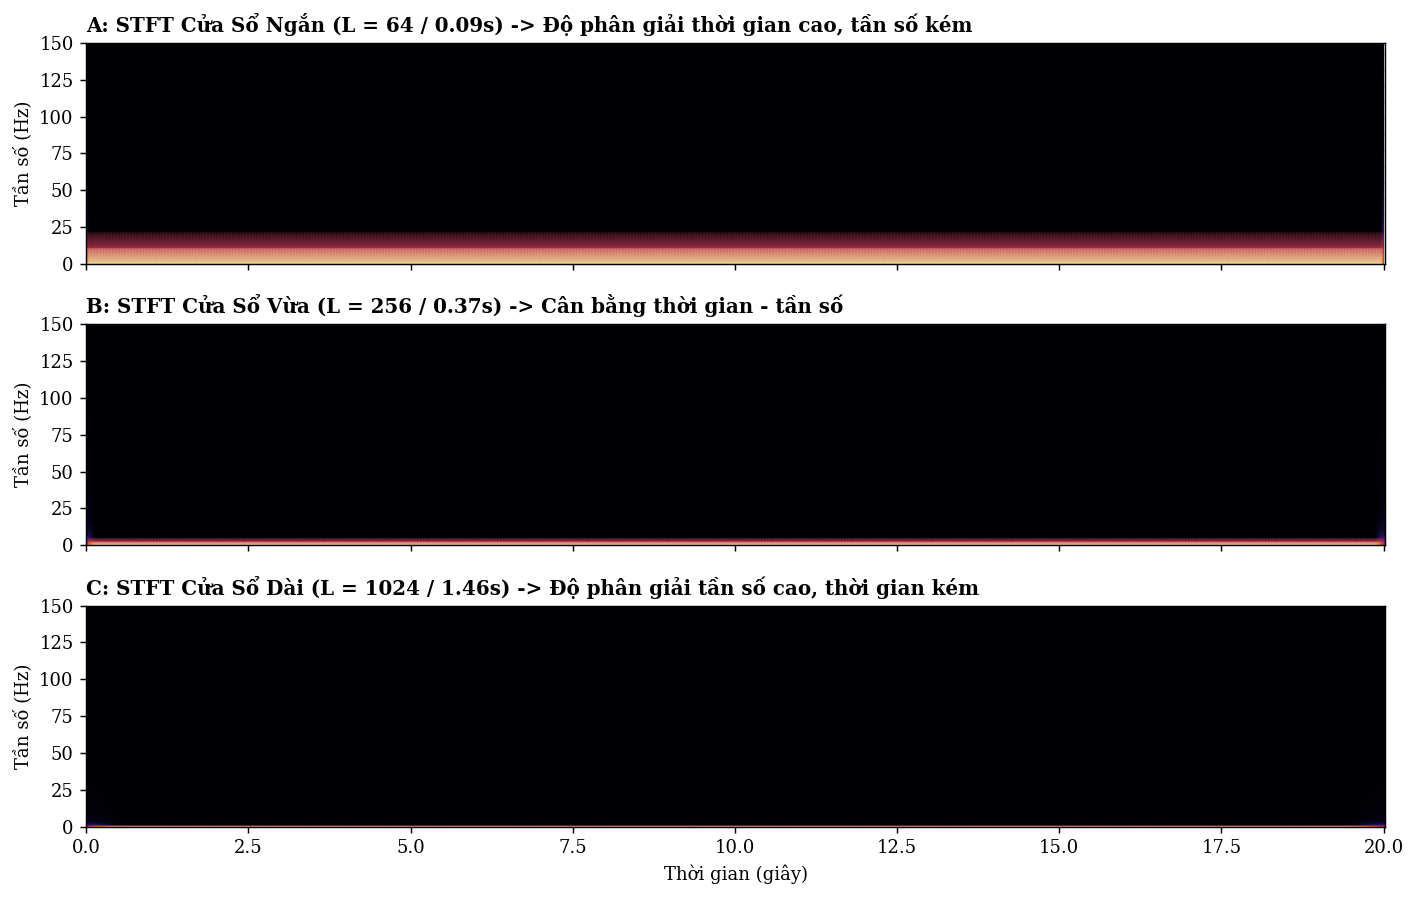

In [2]:
# So sánh 3 kích thước cửa sổ trên tín hiệu EMG (Fs = 700 Hz)
# Cửa sổ ngắn: 64 mẫu (~0.09s), Vừa: 256 mẫu (~0.37s), Dài: 1024 mẫu (~1.46s)
win_short = 64
win_mid = 256
win_long = 1024

f_s, t_s, Z_s = signal.stft(emg_seg, fs=fs_emg, nperseg=win_short, noverlap=win_short-16)
f_m, t_m, Z_m = signal.stft(emg_seg, fs=fs_emg, nperseg=win_mid, noverlap=win_mid-32)
f_l, t_l, Z_l = signal.stft(emg_seg, fs=fs_emg, nperseg=win_long, noverlap=win_long-64)

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)

# 1. Cửa sổ ngắn
im1 = axes[0].pcolormesh(t_s, f_s, np.abs(Z_s), shading='gouraud', cmap='inferno')
axes[0].set_ylim([0, 150])
axes[0].set_ylabel('Tần số (Hz)')
axes[0].set_title('A: STFT Cửa Sổ Ngắn (L = 64 / 0.09s) -> Độ phân giải thời gian cao, tần số kém', loc='left')

# 2. Cửa sổ vừa
im2 = axes[1].pcolormesh(t_m, f_m, np.abs(Z_m), shading='gouraud', cmap='inferno')
axes[1].set_ylim([0, 150])
axes[1].set_ylabel('Tần số (Hz)')
axes[1].set_title('B: STFT Cửa Sổ Vừa (L = 256 / 0.37s) -> Cân bằng thời gian - tần số', loc='left')

# 3. Cửa sổ dài
im3 = axes[2].pcolormesh(t_l, f_l, np.abs(Z_l), shading='gouraud', cmap='inferno')
axes[2].set_ylim([0, 150])
axes[2].set_ylabel('Tần số (Hz)')
axes[2].set_xlabel('Thời gian (giây)')
axes[2].set_title('C: STFT Cửa Sổ Dài (L = 1024 / 1.46s) -> Độ phân giải tần số cao, thời gian kém', loc='left')

plt.tight_layout()
plt.show()


## 2. Spectrogram của Tín hiệu PPG Khi Có Vận Động
Khảo sát sự biến thiên của dải tần số nhịp tim trên tín hiệu PPG/BVP theo thời gian.


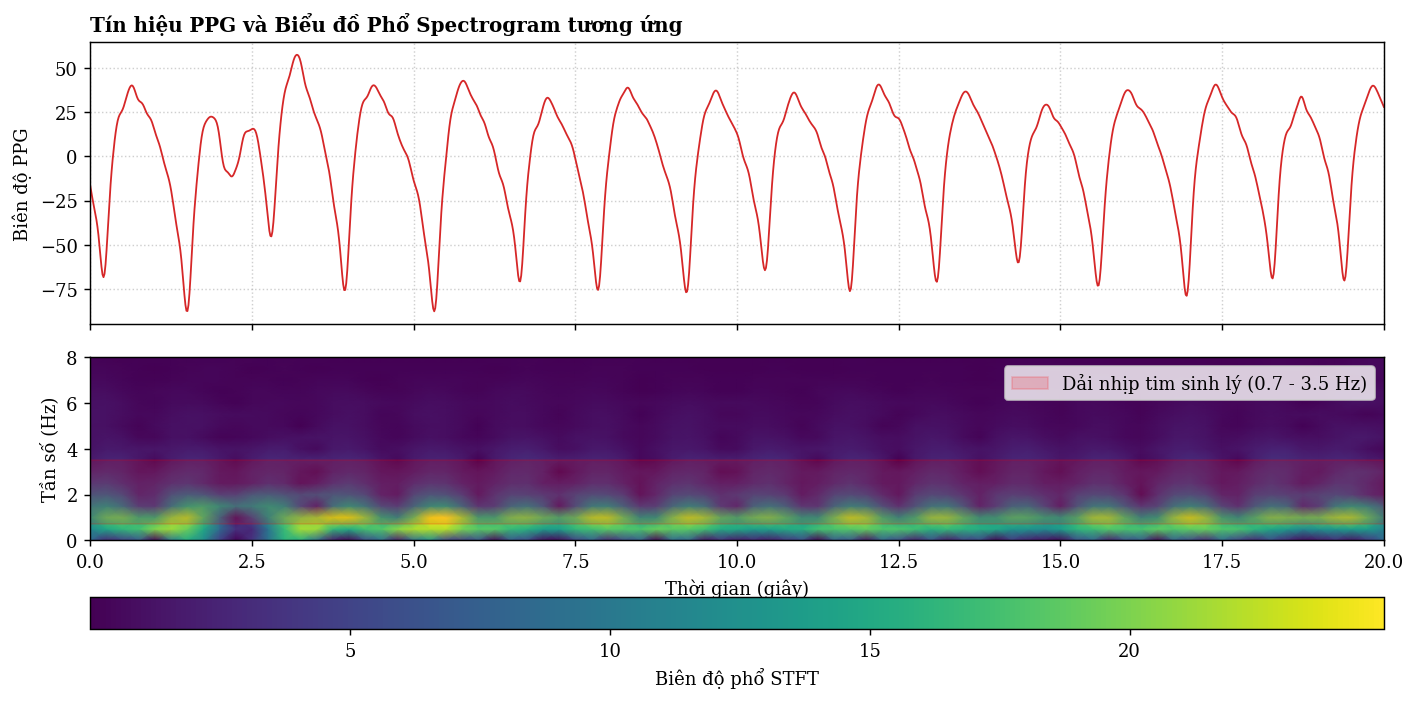

In [3]:
# Phân tích STFT cho BVP (PPG) với nperseg = 128 (2 giây)
nper_bvp = 128
nover_bvp = 112
f_bvp, t_bvp, Z_bvp = signal.stft(bvp_seg, fs=fs_bvp, nperseg=nper_bvp, noverlap=nover_bvp)
spec_bvp = np.abs(Z_bvp)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
t_bvp_axis = np.linspace(0, dur, len(bvp_seg))
ax1.plot(t_bvp_axis, bvp_seg, color='#d62728', lw=1.0)
ax1.set_ylabel('Biên độ PPG')
ax1.set_title('Tín hiệu PPG và Biểu đồ Phổ Spectrogram tương ứng', loc='left')
ax1.grid(True, linestyle=':', alpha=0.6)

pcm = ax2.pcolormesh(t_bvp, f_bvp, spec_bvp, shading='gouraud', cmap='viridis')
ax2.axhspan(0.7, 3.5, color='red', alpha=0.15, label='Dải nhịp tim sinh lý (0.7 - 3.5 Hz)')
ax2.set_ylim([0, 8.0])
ax2.set_ylabel('Tần số (Hz)')
ax2.set_xlabel('Thời gian (giây)')
ax2.legend(loc='upper right')

cbar = fig.colorbar(pcm, ax=ax2, orientation='horizontal', pad=0.2, aspect=40)
cbar.set_label('Biên độ phổ STFT')

plt.tight_layout()
plt.show()


## Kết Luận Notebook 2:
- STFT đã cải thiện nhược điểm của FFT bằng cách cung cấp thông tin 2 chiều Thời gian - Tần số.
- Tuy nhiên, độ phân giải vẫn bị cố định bởi kích thước cửa sổ định trước và hàm cơ sở hình sin cứng nhắc, không thể thích ứng với các biến đổi phi tuyến cục bộ của tín hiệu sinh lý.
